# Bending Water: A Relaxed Scan

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/10-bending-scan.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


Why is water bent? We can find out by forcing it to bend through a range of angles, all the way to linear, and watching how the energy and the orbitals respond. At each angle we let the bond lengths relax. This is a **relaxed scan** (also called a constrained optimization).

## What You Will Learn
- How to **freeze** a coordinate during an optimization.
- What the **barrier to linearity** of water is.
- How a frequency calculation identifies linear water as a **saddle point** (an imaginary frequency).
- How the orbital energies change with angle: a **Walsh diagram**.

In [2]:
psi4.set_output_file("output/10-bending-scan.out", False);
psi4.set_options({"basis": "6-31g*", "scf_type": "pk"})
h2kJ = psi4.constants.hartree2kJmol

## 1. The Scan

```{note} Psi4 settings in this cell
:class: dropdown
`frozen_bend: "2 1 3"`
: Keeps the H–O–H angle (atoms 2–1–3, counting from **1** as in the geometry) at its starting value while everything else is optimized. We set the starting angle in the *Z-matrix*.
: *Alternatives:* `frozen_distance` and `frozen_dihedral` freeze other coordinates. `ranged_bend: "2 1 3 100.0 110.0"` lets the angle move only within a range. A **rigid scan** (just `psi4.energy()` at each angle, as in the *Optimization* notebook) is cheaper but less realistic, because the bond lengths cannot respond.

`hf/6-31g*`
: Cheap enough for about 20 optimizations in well under a minute. *Alternatives:* `b3lyp/6-31g*` or `mp2/cc-pvtz` give a barrier closer to experiment.

Why stop at 178°?
: The internal coordinates used by the optimizer cannot describe a bend at exactly 180°. Exactly linear water is handled separately below.
```

In [3]:
angles = np.arange(80.0, 179.0, 6.0)
angles = np.append(angles, 178.0)

scan = []
xyz_frames = []
for angle in angles:
    mol = psi4.geometry(f"""
    0 1
    O
    H 1 0.95
    H 1 0.95 2 {angle}
    """)
    psi4.set_options({"frozen_bend": "2 1 3"})
    E, w = psi4.optimize("hf", molecule=mol, return_wfn=True)

    # orbital energies of the three highest occupied orbitals, labelled by symmetry
    char_table = mol.point_group().char_table()
    occupied = []
    for h in range(w.nirrep()):
        for i in range(w.doccpi()[h]):
            occupied.append((w.epsilon_a().nph[h][i], f"{i + 1}{char_table.gamma(h).symbol().lower()}"))
    orbital_energies = {label: eps for eps, label in occupied}

    scan.append({"angle": angle, "E": E, "r(O-H)": ph.bond_length(mol, 0, 1), **orbital_energies})
    xyz_frames.append(mol.save_string_xyz_file())

psi4.core.clean_options()                       # remove frozen_bend before the next calculations
psi4.set_options({"basis": "6-31g*", "scf_type": "pk"})

scan = pd.DataFrame(scan)
scan["E rel (kJ/mol)"] = (scan["E"] - scan["E"].min()) * h2kJ
scan[["angle", "r(O-H)", "E rel (kJ/mol)"]].round(3)

Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


... (9 outputs left out)

Optimizer: Optimization complete!


Optimizer: Optimization complete!


Optimizer: Optimization complete!


,angle,r(O-H),E rel (kJ/mol)
0,80.0,0.963,54.602
1,86.0,0.958,31.199
2,92.0,0.954,14.512
3,98.0,0.951,4.241
4,104.0,0.948,0.000
5,110.0,0.945,1.319
6,116.0,0.943,7.641
7,122.0,0.941,18.316
8,128.0,0.939,32.592
9,134.0,0.937,49.608


## 2. Linear Water

To get exactly linear water we start from a linear structure. Symmetry ($D_{\infty h}$, handled by *Psi4* as $D_{2h}$) keeps it linear, so an ordinary optimization relaxes only the bond lengths. Then a frequency calculation tells us what kind of stationary point it is.

In [4]:
linear = psi4.geometry("""
0 1
O  0.0  0.0  0.0
H  0.0  0.0  0.95
H  0.0  0.0 -0.95
""")
E_lin = psi4.optimize("hf", molecule=linear)
E_lin, w_lin = psi4.frequency("hf", molecule=linear, return_wfn=True)

print("Point group:", linear.schoenflies_symbol())
print(f"r(O-H) = {ph.bond_length(linear, 0, 1):.4f} Å")
print("Frequencies (cm-1):", ", ".join(f"{f:.1f}" for f in w_lin.frequencies().np))

barrier = (E_lin - scan["E"].min()) * h2kJ
print(f"Barrier to linearity: {barrier:.1f} kJ/mol   (experiment: about 133 kJ/mol)")

Optimizer: Optimization complete!


Point group: d2h
r(O-H) = 0.9248 Å
Frequencies (cm-1): -1872.8, -1872.8, 4256.5, 4677.6
Barrier to linearity: 156.4 kJ/mol   (experiment: about 133 kJ/mol)


The negative frequency, printed twice, is an **imaginary frequency**: the curvature along the bending motion is negative, so linear water sits at the top of a hill. It appears twice because a linear molecule can bend in two perpendicular planes. Linear water is a **saddle point** (here the transition state for inverting the molecule), not a stable structure, even though the optimizer converged there.

## 3. Energy and Bond Length along the Scan

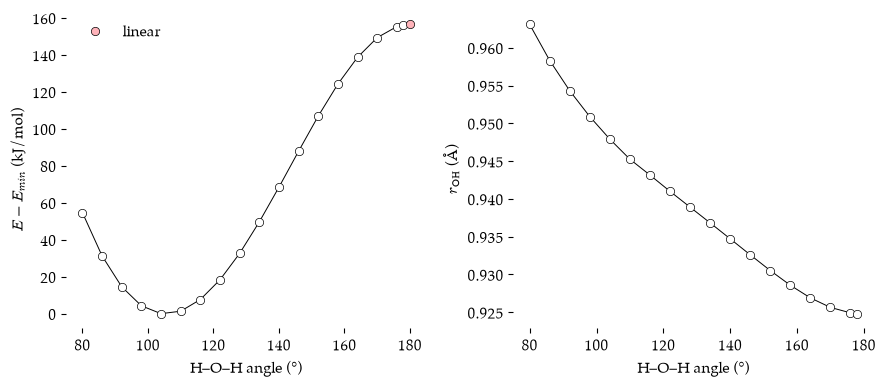

In [5]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))
axs[0].plot(scan["angle"], scan["E rel (kJ/mol)"], color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
axs[0].plot([180], [barrier], linestyle="none", marker="o", markerfacecolor="#FFB3BA",
            markeredgecolor="black", markeredgewidth=0.5, label="linear")
axs[0].set_xlabel("H–O–H angle (°)")
axs[0].set_ylabel(r"$E - E_{min}$ (kJ/mol)")
axs[0].legend()

axs[1].plot(scan["angle"], scan["r(O-H)"], color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
axs[1].set_xlabel("H–O–H angle (°)")
axs[1].set_ylabel(r"$r_{\mathrm{OH}}$ (Å)")
plt.tight_layout()
plt.show()

The bonds get slightly **shorter** as the molecule opens up: the oxygen orbitals used for bonding gain more $s$ character.

## 4. A Walsh Diagram

Now we plot the energies of the three highest occupied orbitals against the angle.

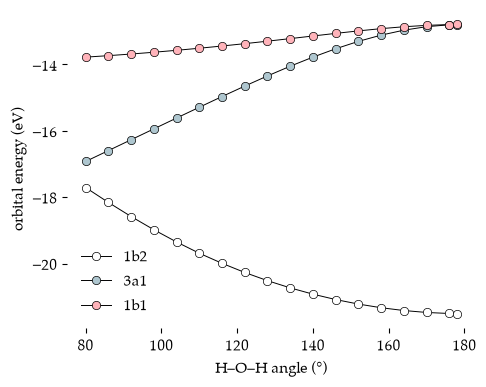

In [6]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
for label, color in [("1b2", "white"), ("3a1", "#AEC6CF"), ("1b1", "#FFB3BA")]:
    ax.plot(scan["angle"], scan[label] * psi4.constants.hartree2ev, color="black", linewidth=0.7, marker="o",
            markerfacecolor=color, markeredgecolor="black", markeredgewidth=0.5, label=label)
ax.set_xlabel("H–O–H angle (°)")
ax.set_ylabel("orbital energy (eV)")
ax.legend()
plt.show()

- $1b_1$, the out-of-plane lone pair, is a pure O 2p orbital and rises only slightly (about 1 eV).
- $3a_1$ **rises steeply** (about 4 eV) as the molecule straightens. In bent water it mixes O 2s character into the in-plane lone pair and gains some O–H bonding. At 180° it becomes a pure 2p orbital, degenerate with $1b_1$ (together they become the $\pi$ lone pairs of linear water).
- $1b_2$ **falls** by a similar amount, because its O–H bonding improves as the hydrogens move to opposite sides of the oxygen.

So two effects compete. The O–H bonding orbital ($1b_2$) prefers a linear molecule; the in-plane lone pair ($3a_1$) strongly prefers a bent one. With 8 valence electrons $3a_1$ is filled, and the total energy (the left-hand plot in section 3) shows that bending wins. Molecules with only 4 valence electrons, such as BeH₂, leave $3a_1$ empty and are linear. (The sum of orbital energies is not the total energy, so a Walsh diagram is a qualitative argument; the scan itself gives the quantitative answer.)

## 5. Watching the Scan

In [7]:
view = py3Dmol.view(width=400, height=300)
view.addModelsAsFrames("".join(xyz_frames), "xyz")
view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
view.setBackgroundColor("#f2f2f2")
view.zoomTo()
view.animate({"loop": "backAndForth", "interval": 300})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

```{note} Note on orientation
:class: dropdown
*Psi4* re-orients each structure into its standard frame, so the molecule may appear to jump between frames. Adding `no_reorient` and `no_com` to the geometry string keeps every frame in the same orientation.
```

## Summary
- `frozen_bend` (and its relatives) let you scan one coordinate while optimizing the rest.
- An optimization can converge on a saddle point; frequencies reveal it with imaginary values.
- A Walsh diagram shows which orbitals favour bending, explaining the shape of water.